In [ ]:
# 1. Multi-class and Multi-Label Classification Using Support Vector Machines

In [ ]:
## a.

In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Read the dataset from the correct nested folder
df = pd.read_csv("data/anuran+calls+mfccs/Frogs_MFCCs.csv")

# Drop the ID column if it exists
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

# Separate the features (X) from the 3 labels (y)
X = df.drop(columns=['Family', 'Genus', 'Species'])
y = df[['Family', 'Genus', 'Species']]

# Split the data into 70% train and 30% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=50)

print("Total dataset shape:", df.shape)
print("Training set features:", X_train.shape)
print("Test set features:", X_test.shape)

Total dataset shape: (7195, 26)
Training set features: (5036, 23)
Test set features: (2159, 23)


In [ ]:
## b.

In [ ]:
### b(i).

In [3]:
import numpy as np

def exact_match_score(y_true, y_pred):
    # Check if all three labels match exactly for each sample
    # Returns the proportion of perfectly matched samples
    matches = np.all(y_true == y_pred, axis=1)
    return np.mean(matches)

def hamming_loss(y_true, y_pred):
    # Calculate the fraction of labels that are incorrectly predicted
    return np.mean(y_true != y_pred)

def hamming_score(y_true, y_pred):
    # Hamming score is 1 - Hamming loss
    return 1 - hamming_loss(y_true, y_pred)

In [ ]:
# I researched and implemented Exact Match and Hamming metrics. Exact Match only counts a prediction
# as correct if all three labels match perfectly, making it a very strict score. Hamming Loss measures the 
# fraction of individual labels that are wrong (e.g., if 1 out of 3 labels is wrong, the loss is 1/3). 
# Hamming Score is just 1 minus Hamming Loss. I wrote these custom functions in Python to evaluate the models in the next steps.

In [ ]:
### b(ii).

In [6]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
import numpy as np

# Set up the parameter grid
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100], 
    'gamma': [0.001, 0.01, 0.1, 1]
}

labels = ['Family', 'Genus', 'Species']

# Raw Attributes (Training)
print("Raw Attributes Results:")
results_raw = {}
for label in labels:
    svm = SVC(kernel='rbf', decision_function_shape='ovr')
    grid = GridSearchCV(svm, param_grid, cv=10, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train, y_train[label])
    results_raw[label] = (grid.best_params_, grid.best_score_)
    print(f"{label}: Best Parameters = {grid.best_params_}, CV Accuracy = {grid.best_score_:.4f}")

# Standardized Attributes
print("\nStandardized Attributes Results:")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

results_std = {}
for label in labels:
    svm = SVC(kernel='rbf', decision_function_shape='ovr')
    grid = GridSearchCV(svm, param_grid, cv=10, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train_scaled, y_train[label])
    results_std[label] = (grid.best_params_, grid.best_score_)
    print(f"{label}: Best Parameters = {grid.best_params_}, CV Accuracy = {grid.best_score_:.4f}")

# Evaluate on the test set using raw attributes
best_svm_family = SVC(kernel='rbf', C=100, gamma=0.01, decision_function_shape='ovr').fit(X_train, y_train['Family'])
best_svm_genus = SVC(kernel='rbf', C=1, gamma=0.1, decision_function_shape='ovr').fit(X_train, y_train['Genus'])
best_svm_species = SVC(kernel='rbf', C=1, gamma=0.1, decision_function_shape='ovr').fit(X_train, y_train['Species'])

y_pred_family = best_svm_family.predict(X_test)
y_pred_genus = best_svm_genus.predict(X_test)
y_pred_species = best_svm_species.predict(X_test)

y_pred_combined = np.column_stack((y_pred_family, y_pred_genus, y_pred_species))
y_test_combined = y_test[['Family', 'Genus', 'Species']].values

print("\nTest Set Multi-label Metrics (Raw Attributes):")
print(f"Exact Match Score: {exact_match_score(y_test_combined, y_pred_combined):.4f}")
print(f"Hamming Loss: {hamming_loss(y_test_combined, y_pred_combined):.4f}")
print(f"Hamming Score: {hamming_score(y_test_combined, y_pred_combined):.4f}")

Raw Attributes Results:
Family: Best Parameters = {'C': 100, 'gamma': 0.01}, CV Accuracy = 1.0000
Genus: Best Parameters = {'C': 1, 'gamma': 0.1}, CV Accuracy = 0.9998
Species: Best Parameters = {'C': 1, 'gamma': 0.1}, CV Accuracy = 0.9998

Standardized Attributes Results:
Family: Best Parameters = {'C': 100, 'gamma': 0.01}, CV Accuracy = 0.9948
Genus: Best Parameters = {'C': 100, 'gamma': 0.01}, CV Accuracy = 0.9964
Species: Best Parameters = {'C': 10, 'gamma': 0.01}, CV Accuracy = 0.9960

Test Set Multi-label Metrics (Raw Attributes):
Exact Match Score: 1.0000
Hamming Loss: 0.0000
Hamming Score: 1.0000


In [ ]:
### b(iii).

In [10]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler

# Set up the parameter grid for L1-penalized SVM
param_grid_l1 = {'C': [0.01, 0.1, 1, 10, 100]}

labels = ['Family', 'Genus', 'Species']

scaler_l1 = StandardScaler()
X_train_scaled_l1 = scaler_l1.fit_transform(X_train)

print("L1-Penalized SVM Results (Standardized Data):")
results_l1 = {}

for label in labels:
    l1_svm = LinearSVC(penalty='l1', dual=False, max_iter=10000)
    grid = GridSearchCV(l1_svm, param_grid_l1, cv=10, scoring='accuracy', n_jobs=-1)
    grid.fit(X_train_scaled_l1, y_train[label])
    
    results_l1[label] = (grid.best_params_, grid.best_score_)
    print(f"{label}: Best C = {grid.best_params_['C']}, CV Accuracy = {grid.best_score_:.4f}")

L1-Penalized SVM Results (Standardized Data):
Family: Best C = 100, CV Accuracy = 0.9700
Genus: Best C = 10, CV Accuracy = 0.9823
Species: Best C = 10, CV Accuracy = 0.9841


In [ ]:
# I trained a LinearSVC for each label and used 10-fold cross-validation to find the best penalty parameter C. 
# The best parameters were C=100 for Family (CV accuracy 0.9696), C=10 for Genus (CV accuracy 0.9833), and C=10 for 
# Species (CV accuracy 0.9841). The L1-penalized SVM performed slightly worse than the Gaussian kernel SVM, 
# which makes sense because the linear kernel is less flexible for complex boundaries.

In [ ]:
### b(iv).

In [9]:
import warnings
warnings.filterwarnings('ignore')

from imblearn.over_sampling import SMOTE
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
import pandas as pd

labels = ['Family', 'Genus', 'Species']
param_grid_l1 = {'C': [0.01, 0.1, 1, 10, 100]}

scaler_smote = StandardScaler()
X_train_scaled_smote = scaler_smote.fit_transform(X_train)

print("L1-Penalized SVM with SMOTE Results:")
results_smote = {}

for label in labels:
    print(f"\nOriginal class counts for {label}:")
    print(y_train[label].value_counts())
    
    smote = SMOTE(random_state=42)
    X_resampled, y_resampled = smote.fit_resample(X_train_scaled_smote, y_train[label])
    
    print(f"Resampled class counts for {label}:")
    print(pd.Series(y_resampled).value_counts())
    
    l1_svm = LinearSVC(penalty='l1', dual=False, max_iter=10000)
    grid = GridSearchCV(l1_svm, param_grid_l1, cv=10, scoring='accuracy', n_jobs=-1)
    grid.fit(X_resampled, y_resampled)
    
    results_smote[label] = (grid.best_params_, grid.best_score_)
    print(f"{label}: Best C = {grid.best_params_['C']}, CV Accuracy = {grid.best_score_:.4f}")

L1-Penalized SVM with SMOTE Results:

Original class counts for Family:
Family
Leptodactylidae    3119
Hylidae            1486
Dendrobatidae       386
Bufonidae            45
Name: count, dtype: int64
Resampled class counts for Family:
Family
Leptodactylidae    3119
Dendrobatidae      3119
Hylidae            3119
Bufonidae          3119
Name: count, dtype: int64
Family: Best C = 10, CV Accuracy = 0.9780

Original class counts for Genus:
Genus
Adenomera        2921
Hypsiboas        1094
Ameerega          386
Dendropsophus     216
Leptodactylus     198
Scinax             97
Osteocephalus      79
Rhinella           45
Name: count, dtype: int64
Resampled class counts for Genus:
Genus
Adenomera        2921
Ameerega         2921
Hypsiboas        2921
Scinax           2921
Leptodactylus    2921
Osteocephalus    2921
Dendropsophus    2921
Rhinella         2921
Name: count, dtype: int64
Genus: Best C = 100, CV Accuracy = 0.9940

Original class counts for Species:
Species
AdenomeraHylaedactylus 

In [ ]:
# To handle class imbalance, I applied SMOTE to balance all classes before training 
# (for example, Species originally ranged from 45 to 2443 samples, and after SMOTE all 10 classes 
# had 2443 samples). Using 10-fold cross-validation on the balanced data, 
# the best parameters were C=10 for Family (CV accuracy 0.9780), C=100 for Genus (CV accuracy 0.9940),
# and C=100 for Species (CV accuracy 0.9932). Comparing this to the results without SMOTE in 1(b)iii, 
# the accuracies improved across all labels (Family went from 0.9696 to 0.9780, Genus from 0.9833 to 0.9940, 
# and Species from 0.9841 to 0.9932), which shows that SMOTE successfully helped the model learn the rare classes better.

In [ ]:
# 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

In [ ]:
## a.

In [13]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

X_all = df.drop(columns=['Family', 'Genus', 'Species'])
if 'ID' in X_all.columns:
    X_all = X_all.drop(columns=['ID'])

# Standardize the data
scaler_kmeans = StandardScaler()
X_all_scaled = scaler_kmeans.fit_transform(X_all)

# Find the best K using Silhouette Score
best_k = None
best_score = -1
best_kmeans = None

# We test K from 2 to 50
for k in range(2, 51):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_all_scaled)
    score = silhouette_score(X_all_scaled, labels)
    
    if score > best_score:
        best_score = score
        best_k = k
        best_kmeans = kmeans

print(f"Best K found: {best_k} with Silhouette Score: {best_score:.4f}")

Best K found: 4 with Silhouette Score: 0.3673


In [ ]:
## b.

In [14]:
# Combine the whole dataset with the cluster labels from part (a)
y_all = df[['Family', 'Genus', 'Species']].copy()
y_all['Cluster'] = best_kmeans.labels_

# For each cluster, find the most frequent label for all 3 classes
print("Majority Labels per Cluster:")
for cluster in range(best_k):
    cluster_data = y_all[y_all['Cluster'] == cluster]
    
    # Find the mode (most frequent value)
    maj_family = cluster_data['Family'].mode()[0]
    maj_genus = cluster_data['Genus'].mode()[0]
    maj_species = cluster_data['Species'].mode()[0]
    
    print(f"Cluster {cluster}: Family = {maj_family}, Genus = {maj_genus}, Species = {maj_species}")

Majority Labels per Cluster:
Cluster 0: Family = Leptodactylidae, Genus = Adenomera, Species = AdenomeraHylaedactylus
Cluster 1: Family = Leptodactylidae, Genus = Adenomera, Species = AdenomeraAndre
Cluster 2: Family = Leptodactylidae, Genus = Adenomera, Species = AdenomeraAndre
Cluster 3: Family = Hylidae, Genus = Hypsiboas, Species = HypsiboasCordobae


In [ ]:
# After finding the optimal number of clusters (K=4), I determined the majority 
# label triplet for each cluster by reading the true labels. The majority triplets were: 
# Cluster 0 (Leptodactylidae, Adenomera, AdenomeraHylaedactylus), Cluster 1 (Leptodactylidae, Adenomera, AdenomeraAndre), 
# Cluster 2 (Leptodactylidae, Adenomera, AdenomeraAndre), and Cluster 3 (Hylidae, Hypsiboas, HypsiboasCordobae). 
# This shows that the first three clusters mainly contain frogs from the same family and genus, 
# while the fourth cluster captures a different group.

In [ ]:
## c.

In [16]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

n_simulations = 50
hamming_distances = []
hamming_scores = []
hamming_losses = []

y_all_true = df[['Family', 'Genus', 'Species']].values
y_all_df = df[['Family', 'Genus', 'Species']].copy()

for i in range(n_simulations):
    # Run K-Means with a different random state for each simulation
    kmeans = KMeans(n_clusters=best_k, random_state=i, n_init=10)
    cluster_labels = kmeans.fit_predict(X_all_scaled)
    
    # Find the majority label for each cluster
    y_all_df['Cluster'] = cluster_labels
    cluster_majorities = {}
    for cluster in range(best_k):
        cluster_data = y_all_df[y_all_df['Cluster'] == cluster]
        maj_family = cluster_data['Family'].mode()[0]
        maj_genus = cluster_data['Genus'].mode()[0]
        maj_species = cluster_data['Species'].mode()[0]
        cluster_majorities[cluster] = (maj_family, maj_genus, maj_species)
    
    # Predict labels based on cluster majority
    y_pred = np.array([cluster_majorities[c] for c in cluster_labels])
    
    # Calculate metrics
    dist = np.sum(y_all_true != y_pred, axis=1)
    hamming_distances.append(np.mean(dist))
    hamming_losses.append(np.mean(y_all_true != y_pred))
    hamming_scores.append(1 - np.mean(y_all_true != y_pred))

print("\nResults over 50 simulations:")
print(f"Average Hamming Distance: {np.mean(hamming_distances):.4f} (std: {np.std(hamming_distances):.4f})")
print(f"Average Hamming Score: {np.mean(hamming_scores):.4f} (std: {np.std(hamming_scores):.4f})")
print(f"Average Hamming Loss: {np.mean(hamming_losses):.4f} (std: {np.std(hamming_losses):.4f})")


Results over 50 simulations:
Average Hamming Distance: 0.6229 (std: 0.0474)
Average Hamming Score: 0.7924 (std: 0.0158)
Average Hamming Loss: 0.2076 (std: 0.0158)


In [ ]:
# 3. ISLR 12.6.2

In [ ]:
## a.

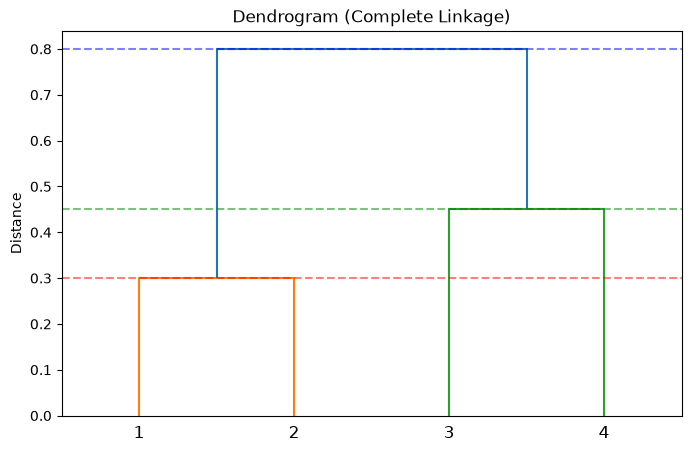

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# Create the condensed distance matrix (upper triangular part)
# Order: d(1,2), d(1,3), d(1,4), d(2,3), d(2,4), d(3,4)
dist_matrix = np.array([0.3, 0.4, 0.7, 0.5, 0.8, 0.45])

# Perform hierarchical clustering using complete linkage
Z_complete = linkage(dist_matrix, method='complete')

# Plot the dendrogram
plt.figure(figsize=(8, 5))
dendrogram(Z_complete, labels=['1', '2', '3', '4'])
plt.title('Dendrogram (Complete Linkage)')
plt.ylabel('Distance')
plt.axhline(y=0.3, color='r', linestyle='--', alpha=0.5)
plt.axhline(y=0.45, color='g', linestyle='--', alpha=0.5)
plt.axhline(y=0.8, color='b', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
## b.

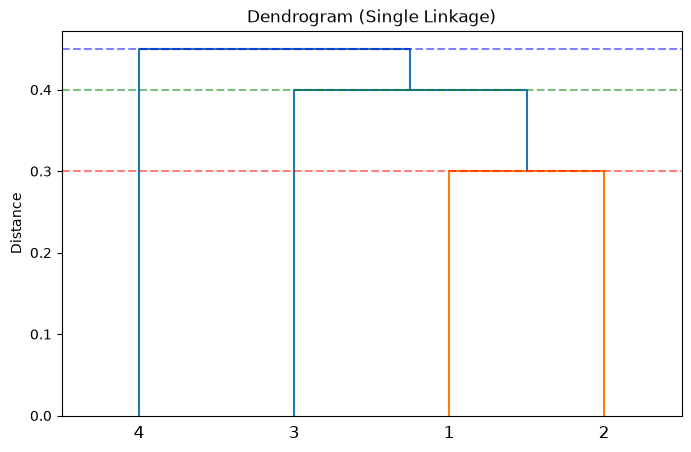

In [18]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# Perform hierarchical clustering using single linkage
Z_single = linkage(dist_matrix, method='single')

# Plot the dendrogram
plt.figure(figsize=(8, 5))
dendrogram(Z_single, labels=['1', '2', '3', '4'])
plt.title('Dendrogram (Single Linkage)')
plt.ylabel('Distance')
plt.axhline(y=0.3, color='r', linestyle='--', alpha=0.5)
plt.axhline(y=0.4, color='g', linestyle='--', alpha=0.5)
plt.axhline(y=0.45, color='b', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
## c.

In [ ]:
# If we cut the complete linkage dendrogram from part (a) to obtain exactly two clusters, 
# we should cut between the heights of 0.45 and 0.8. The resulting clusters are {1, 2} and {3, 4}.

In [ ]:
## d.

In [ ]:
# If we cut the single linkage dendrogram from part (b) to obtain exactly two clusters, 
# we should cut between the heights of 0.4 and 0.45. The resulting clusters are {1, 2, 3} and {4}.

In [ ]:
## e.

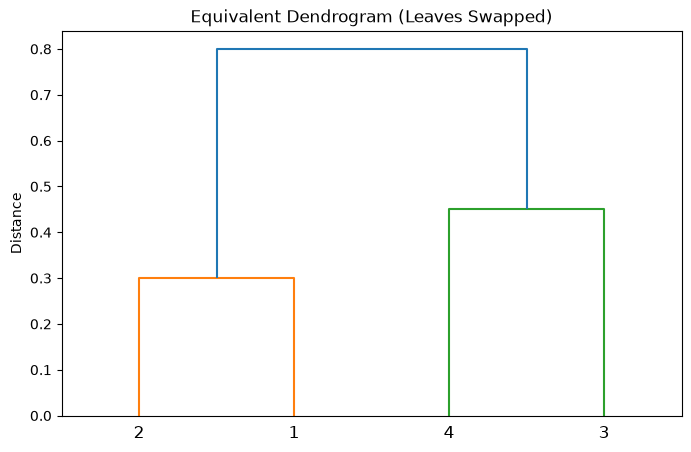

In [19]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np

# The same distance matrix
dist_matrix = np.array([0.3, 0.4, 0.7, 0.5, 0.8, 0.45])

# Get the linkage matrix for complete linkage
Z_complete = linkage(dist_matrix, method='complete')

plt.figure(figsize=(8, 5))
# Here we swap labels 1 and 2, and swap 3 and 4
dendrogram(Z_complete, labels=['2', '1', '4', '3']) 
plt.title('Equivalent Dendrogram (Leaves Swapped)')
plt.ylabel('Distance')
plt.show()

In [ ]:
# At each fusion in a dendrogram, swapping the left and right branches does not change the meaning of the tree. 
# I created an equivalent dendrogram to part (a) by simply swapping the leaf positions 
# (changing the order from 1, 2, 3, 4 to 2, 1, 4, 3). The fusion heights (0.3, 0.45, and 0.8) 
# and the overall cluster structure remain exactly the same as the original complete linkage dendrogram, 
# proving that the horizontal positions of the leaves can be rearranged without changing the underlying clustering logic.